# Comparação direta Brasil × CBIS-DDSM: densidade mamária e BI-RADS

Com os laudos do **SISCAN** (`python -m src.scraping.siscan`), passa a ser possível comparar diretamente as duas
variáveis clínicas que o CBIS-DDSM tem e o Brasil publica:

1. **Densidade mamária:** a distribuição é a mesma? E como ela muda com a idade?
2. **BI-RADS:** que tipo de caso cada base contém?
3. **Desempenho do modelo na composição brasileira:** usando as previsões do modelo de imagens
   (`02_imagens_calcificacoes.ipynb`), qual seria a AUC se os casos tivessem a distribuição de densidade do Brasil,
   no geral e por faixa etária?

**Correspondência de escalas:** o laudo do SISCAN informa o *tipo de mama*, que corresponde às categorias de
densidade do BI-RADS usadas no CBIS-DDSM: Adiposa = 1, Predominantemente adiposa = 2, Predominantemente densa = 3,
Densa = 4.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from src import config
from src.processing.cbis import carrega_cbis
from src.visualization import estilo
from src.visualization.estilo import AZUL, LARANJA, VERDE_AGUA, salvar

estilo.aplicar()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

I = config.INTERIM
sis = {n: pd.read_csv(I / f"siscan_{n}.csv") for n in
       ["densidade_ano", "densidade_faixa", "densidade_indicacao", "birads_indicacao", "birads_densidade"]}
sis_birads_ano = pd.read_csv(I / "siscan_birads_ano.csv")
cbis = carrega_cbis()
cbis["breast_density"] = cbis["breast_density"].replace(0, np.nan)
pred = pd.read_csv(config.PROCESSED / "cbis_predicoes_teste_calcificacoes.csv")

DENS = [1, 2, 3, 4]
NOMES_DENS = {1: "1 adiposa", 2: "2 pred. adiposa", 3: "3 pred. densa", 4: "4 densa"}

def distribuicao(contagens):
    s = pd.Series(contagens).reindex(DENS).fillna(0)
    return 100 * s / s.sum()

## 1. Densidade mamária: Brasil × CBIS-DDSM

Brasil: laudos do SISCAN de mulheres, 2018–2022 (mama direita; a esquerda é praticamente igual, ver
`docs/scraping_siscan.md`). CBIS-DDSM: todas as lesões, e separado por tipo de lesão.

Com milhões de exames, qualquer diferença daria "p < 0,001" num qui-quadrado. Por isso medimos o **tamanho** da
diferença:

- **w de Cohen:** 0,1 pequena, 0,3 média, 0,5 grande;
- **distância de variação total (DVT):** a porcentagem dos casos que precisaria "mudar de categoria" para as duas
  distribuições ficarem iguais.

In [2]:
br_dens = distribuicao(sis["densidade_ano"].dropna(subset=["densidade_birads_linha"])
                       .groupby("densidade_birads_linha")["exames"].sum())

def diferenca(p, q):
    p, q = p / 100, q / 100
    return {"w de Cohen": float(np.sqrt((((p - q) ** 2) / q).sum())), "DVT (%)": float(50 * (p - q).abs().sum())}

densidades = pd.DataFrame({
    "Brasil (SISCAN)": br_dens,
    "CBIS: todas as lesões": distribuicao(cbis["breast_density"].value_counts()),
    "CBIS: massas": distribuicao(cbis.query("abnormality_type == 'mass'")["breast_density"].value_counts()),
    "CBIS: calcificações": distribuicao(cbis.query("abnormality_type == 'calcification'")["breast_density"].value_counts()),
    "CBIS: teste do modelo": distribuicao(pred["breast_density"].value_counts()),
}).rename(index=NOMES_DENS)
display(densidades.round(1))

pd.DataFrame({c: diferenca(densidades[c], densidades["Brasil (SISCAN)"]) for c in densidades.columns[1:]}).T.round(3)

,Brasil (SISCAN),CBIS: todas as lesões,CBIS: massas,CBIS: calcificações,CBIS: teste do modelo
1 adiposa,15.70,15.00,19.90,10.60,7.40
2 pred. adiposa,34.10,38.50,44.60,32.90,35.50
3 pred. densa,34.20,30.90,26.50,35.00,35.50
4 densa,16.00,15.50,9.00,21.40,21.60


,w de Cohen,DVT (%)
CBIS: todas as lesões,0.10,4.43
CBIS: massas,0.30,14.71
CBIS: calcificações,0.19,6.21
CBIS: teste do modelo,0.26,8.31


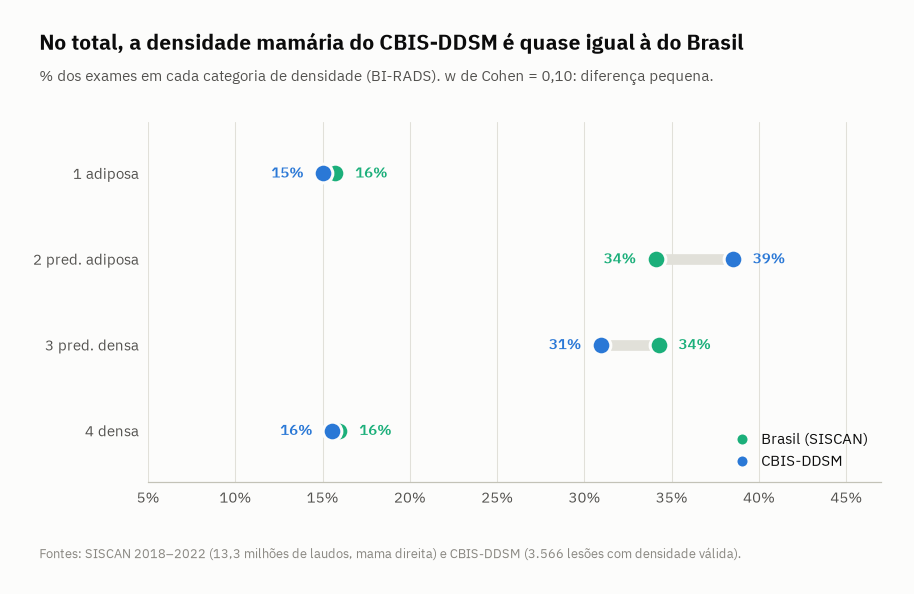

In [3]:
n_br = sis["densidade_ano"].dropna(subset=["densidade_birads_linha"])["exames"].sum()
n_cb = cbis["breast_density"].notna().sum()
w = diferenca(densidades["CBIS: todas as lesões"], densidades["Brasil (SISCAN)"])["w de Cohen"]
br_v = densidades["Brasil (SISCAN)"].to_numpy()
cb_v = densidades["CBIS: todas as lesões"].to_numpy()
y = np.arange(len(densidades))[::-1]

fig, ax = plt.subplots(figsize=(8.6, 3.9))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
for yi, a, b in zip(y, br_v, cb_v):
    ax.plot([a, b], [yi, yi], color=estilo.GRADE, lw=7, solid_capstyle="round", zorder=1)
ax.scatter(br_v, y, s=150, color=VERDE_AGUA, edgecolor=estilo.FUNDO, linewidth=2, zorder=3, label="Brasil (SISCAN)")
ax.scatter(cb_v, y, s=150, color=AZUL, edgecolor=estilo.FUNDO, linewidth=2, zorder=3, label="CBIS-DDSM")
for yi, a, b in zip(y, br_v, cb_v):
    for v, cor, lado in [(a, VERDE_AGUA, -1 if a <= b else 1), (b, AZUL, 1 if a <= b else -1)]:
        ax.annotate(f"{v:.0f}%", (v, yi), xytext=(13 * lado, 0), textcoords="offset points", va="center",
                    ha="left" if lado > 0 else "right", color=cor, fontsize=10, fontweight="semibold")
ax.set_yticks(y, densidades.index)
ax.set_xlim(5, 47)
ax.set_ylim(-0.6, len(y) - 0.4)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.legend(loc="lower right", markerscale=0.7)
estilo.cabecalho(fig, "No total, a densidade mamária do CBIS-DDSM é quase igual à do Brasil",
                 f"% dos exames em cada categoria de densidade (BI-RADS). w de Cohen = {w:.2f}: diferença pequena.")
estilo.rodape(fig, f"Fontes: SISCAN 2018–2022 ({n_br / 1e6:.1f} milhões de laudos, mama direita) e CBIS-DDSM "
                   f"({n_cb:,} lesões com densidade válida).".replace(f"{n_cb:,}", f"{n_cb:,}".replace(",", ".")))
salvar(fig, "15_densidade_brasil_cbis")

### 1.1 Mas a densidade depende muito da idade

No Brasil, a proporção de mamas densas (categorias 3 e 4) por faixa etária. A linha tracejada é a proporção de
mamas densas do CBIS-DDSM, que não informa a idade das pacientes.

In [4]:
fx = sis["densidade_faixa"].dropna(subset=["densidade_birads_linha"])
fx = fx[~fx["coluna"].isin(["Ignorado"])]
ordem_faixas = list(dict.fromkeys(fx["coluna"]))
tab_fx = fx.pivot_table(index="coluna", columns="densidade_birads_linha", values="exames", aggfunc="sum").reindex(ordem_faixas)
tab_fx_pct = 100 * tab_fx.div(tab_fx.sum(axis=1), axis=0)
tab_fx_pct["% densas (3+4)"] = tab_fx_pct[3] + tab_fx_pct[4]
tab_fx_pct["exames"] = tab_fx.sum(axis=1)

def rotulo_faixa(f):
    return (f.replace("Entre ", "").replace(" anos", "").replace(" a ", "–")
             .replace("Acima de 79", "80+").replace("Até 9", "≤9"))

tab_fx_pct.index = [rotulo_faixa(f) for f in tab_fx_pct.index]
tab_fx_pct.round(1)

densidade_birads_linha,1.00,2.00,3.00,4.00,% densas (3+4),exames
≤9,15.00,33.90,35.10,16.00,51.00,"2,102.00"
10–14,9.10,20.10,41.40,29.40,70.80,507.00
15–19,5.00,9.00,37.00,48.90,86.00,"3,261.00"
20–24,6.30,11.20,38.90,43.60,82.50,"9,629.00"
25–29,7.80,14.40,42.30,35.50,77.90,"20,292.00"
30–34,8.70,18.00,43.90,29.30,73.30,"56,986.00"
35–39,9.00,20.90,43.90,26.20,70.20,"285,023.00"
40–44,9.20,22.70,43.70,24.40,68.10,"1,605,179.00"
45–49,10.70,25.80,42.10,21.40,63.50,"2,025,009.00"
50–54,14.50,33.00,36.10,16.30,52.40,"2,787,921.00"


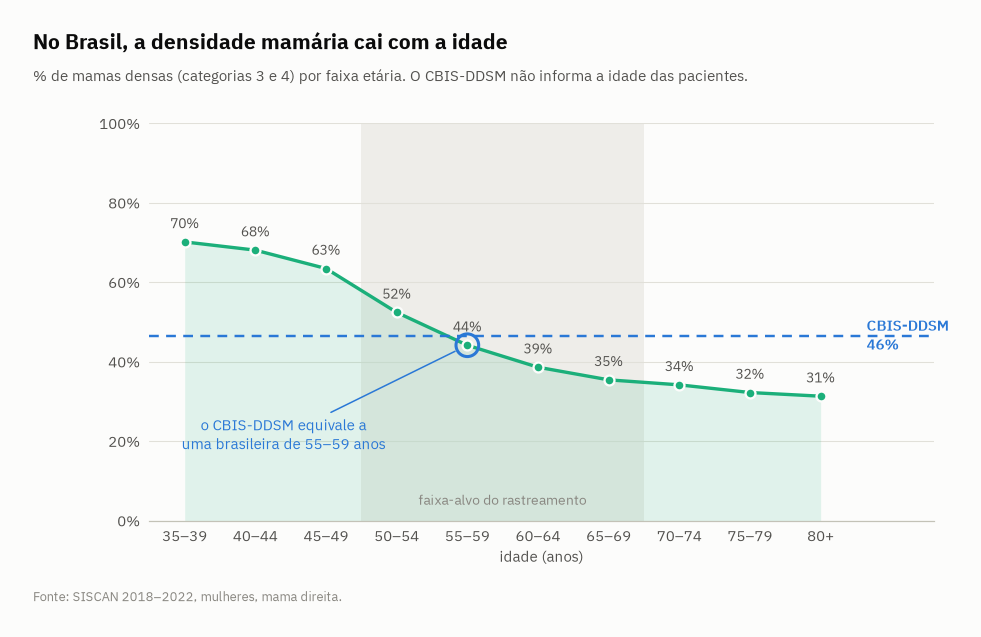

In [5]:
mostrar = tab_fx_pct.loc["35–39":"80+"]
cbis_densas = densidades.loc[["3 pred. densa", "4 densa"], "CBIS: todas as lesões"].sum()
x = np.arange(len(mostrar))
v = mostrar["% densas (3+4)"].to_numpy()
equivalente = (mostrar["% densas (3+4)"] - cbis_densas).abs().idxmin()
xe = mostrar.index.get_loc(equivalente)

fig, ax = plt.subplots(figsize=(9.2, 4.3))
ini, fim = mostrar.index.get_loc("50–54"), mostrar.index.get_loc("65–69")
ax.axvspan(ini - 0.5, fim + 0.5, color=estilo.GRADE, alpha=0.5, lw=0, zorder=0)
ax.text((ini + fim) / 2, 4, "faixa-alvo do rastreamento", ha="center", color=estilo.TINTA_SUAVE, fontsize=9)
ax.fill_between(x, v, color=VERDE_AGUA, alpha=0.12, lw=0)
ax.plot(x, v, color=VERDE_AGUA, marker="o", markersize=6.5, markeredgecolor=estilo.FUNDO, markeredgewidth=1.5)
for xi, yi in zip(x, v):
    ax.annotate(f"{yi:.0f}%", (xi, yi), xytext=(0, 9), textcoords="offset points", ha="center",
                color=estilo.TINTA_SECUNDARIA, fontsize=9)
ax.axhline(cbis_densas, color=AZUL, ls=(0, (4, 3)), lw=1.6)
ax.text(len(x) - 0.35, cbis_densas, f"CBIS-DDSM\n{cbis_densas:.0f}%", color=AZUL, va="center", ha="left",
        fontsize=9.5, fontweight="semibold")
ax.scatter([xe], [v[xe]], s=220, facecolor="none", edgecolor=AZUL, linewidth=2, zorder=4)
ax.annotate(f"o CBIS-DDSM equivale a\numa brasileira de {equivalente} anos", (xe, v[xe]), xytext=(xe - 2.6, 18),
            fontsize=9.5, color=AZUL, ha="center",
            arrowprops=dict(arrowstyle="-", color=AZUL, lw=1, shrinkA=2, shrinkB=9))
ax.set_xticks(x, mostrar.index)
ax.set_xlim(-0.5, len(x) + 0.6)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("idade (anos)")
estilo.cabecalho(fig, "No Brasil, a densidade mamária cai com a idade",
                 "% de mamas densas (categorias 3 e 4) por faixa etária. O CBIS-DDSM não informa a idade das pacientes.")
estilo.rodape(fig, "Fonte: SISCAN 2018–2022, mulheres, mama direita.")
salvar(fig, "16_densidade_por_idade")

## 2. BI-RADS: que tipo de caso cada base contém

A categoria 6 (câncer já confirmado por biópsia) existe no SISCAN, mas não no CBIS-DDSM. Por isso, as distribuições
abaixo usam só as categorias 0 a 5. O SISCAN separa a mamografia de **rastreamento** (mulheres sem sintomas) da
**diagnóstica** (investigação de alteração).

In [6]:
bi = sis["birads_indicacao"]
bi = bi[bi["linha"].str.match(r"Categoria [0-5]$")].copy()
bi["birads"] = bi["linha"].str.extract(r"(\d)").astype(int)
br_bi = bi.pivot_table(index="birads", columns="coluna", values="exames", aggfunc="sum")
cbis_bi = cbis["assessment"].value_counts().reindex(range(6)).fillna(0)

birads = pd.DataFrame({
    "Brasil: rastreamento": 100 * br_bi["Mamog. Rastreamento"] / br_bi["Mamog. Rastreamento"].sum(),
    "Brasil: diagnóstica": 100 * br_bi["Mamog. Diagnostica"] / br_bi["Mamog. Diagnostica"].sum(),
    "CBIS-DDSM": 100 * cbis_bi / cbis_bi.sum(),
})
birads.index = [f"BI-RADS {i}" for i in birads.index]
birads.loc["suspeitos (4 + 5)"] = birads.loc[["BI-RADS 4", "BI-RADS 5"]].sum()
display(birads.round(2))
print("Exames no SISCAN (0–5):", br_bi.sum().astype(int).to_dict())

,Brasil: rastreamento,Brasil: diagnóstica,CBIS-DDSM
BI-RADS 0,11.59,15.29,6.67
BI-RADS 1,34.02,21.94,0.08
BI-RADS 2,51.55,42.43,18.05
BI-RADS 3,1.95,15.20,13.37
BI-RADS 4,0.76,4.09,45.77
BI-RADS 5,0.13,1.04,16.06
suspeitos (4 + 5),0.89,5.12,61.83


Exames no SISCAN (0–5): {'Mamog. Diagnostica': 303806, 'Mamog. Rastreamento': 13117293}


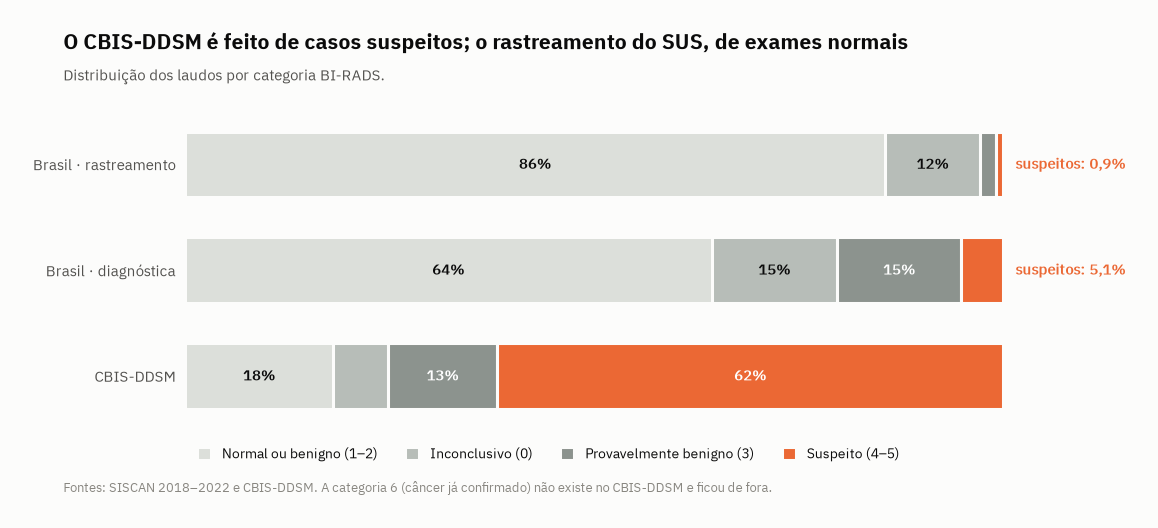

In [7]:
grupos = {
    "Normal ou benigno (1–2)": ["BI-RADS 1", "BI-RADS 2"],
    "Inconclusivo (0)": ["BI-RADS 0"],
    "Provavelmente benigno (3)": ["BI-RADS 3"],
    "Suspeito (4–5)": ["BI-RADS 4", "BI-RADS 5"],
}
cores_grupos = ["#dcdfda", "#b7bdb8", "#8c938e", LARANJA]
fontes_bi = {"Brasil: rastreamento": "Brasil · rastreamento", "Brasil: diagnóstica": "Brasil · diagnóstica",
             "CBIS-DDSM": "CBIS-DDSM"}
composicao = pd.DataFrame({g: birads.loc[c, list(fontes_bi)].sum() for g, c in grupos.items()})
y = np.arange(len(fontes_bi))[::-1]

fig, ax = plt.subplots(figsize=(9.6, 3.3))
ax.grid(False)
ax.spines["bottom"].set_visible(False)
esquerda = np.zeros(len(y))
for (grupo, cor) in zip(grupos, cores_grupos):
    largura = composicao[grupo].to_numpy()
    ax.barh(y, largura, left=esquerda, color=cor, height=0.62, edgecolor=estilo.FUNDO, linewidth=2, label=grupo)
    for yi, l, wd in zip(y, esquerda, largura):
        if wd >= 7:
            ax.text(l + wd / 2, yi, f"{wd:.0f}%", ha="center", va="center", fontsize=10, fontweight="semibold",
                    color="white" if cor in (LARANJA, "#8c938e") else estilo.TINTA)
    esquerda += largura
for yi, wd in zip(y, composicao["Suspeito (4–5)"]):
    if wd < 7:
        ax.text(101.5, yi, f"suspeitos: {wd:.1f}%", va="center", ha="left", color=LARANJA, fontsize=10,
                fontweight="semibold")
ax.set_yticks(y, list(fontes_bi.values()))
ax.set_xlim(0, 100)
ax.set_xticks([])
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.04), ncol=4, fontsize=9)
estilo.cabecalho(fig, "O CBIS-DDSM é feito de casos suspeitos; o rastreamento do SUS, de exames normais",
                 "Distribuição dos laudos por categoria BI-RADS.")
estilo.rodape(fig, "Fontes: SISCAN 2018–2022 e CBIS-DDSM. A categoria 6 (câncer já confirmado) não existe no "
                   "CBIS-DDSM e ficou de fora.")
salvar(fig, "17_birads_brasil_cbis")

### 2.1 As distribuições do SISCAN mudam de 2018 a 2022?

As comparações acima juntam os cinco anos. Isso só é razoável se a composição dos laudos for estável no período,
inclusive em 2020, quando a pandemia derrubou o número de exames. Para cada ano, comparamos a distribuição de
densidade e de BI-RADS com a do período inteiro (w de Cohen; abaixo de 0,1 a diferença é considerada pequena).
O BI-RADS aqui inclui todas as indicações (rastreamento e diagnóstica), porque a consulta por ano não as separa.

In [8]:
dens_ano = (sis["densidade_ano"].dropna(subset=["densidade_birads_linha"])
            .pivot_table(index="coluna", columns="densidade_birads_linha", values="exames", aggfunc="sum")[DENS])
bi_ano = sis_birads_ano[sis_birads_ano["linha"].str.match(r"Categoria [0-5]$")].copy()
bi_ano["birads"] = bi_ano["linha"].str.extract(r"(\d)").astype(int)
bi_ano = bi_ano.pivot_table(index="coluna", columns="birads", values="exames", aggfunc="sum")

def w_cohen(p, q):
    return float(np.sqrt((((p - q) ** 2) / q).sum()))

pct_dens = dens_ano.div(dens_ano.sum(axis=1), axis=0)
pct_bi = bi_ano.div(bi_ano.sum(axis=1), axis=0)
total_dens = dens_ano.sum() / dens_ano.sum().sum()
total_bi = bi_ano.sum() / bi_ano.sum().sum()
cbis_dens = densidades["CBIS: todas as lesões"].to_numpy() / 100

estabilidade = pd.DataFrame({
    "exames (densidade)": dens_ano.sum(axis=1).astype(int),
    "% mamas densas (3+4)": 100 * (pct_dens[3] + pct_dens[4]),
    "w densidade vs período": [w_cohen(pct_dens.loc[a], total_dens) for a in pct_dens.index],
    "w CBIS-DDSM vs ano": [w_cohen(cbis_dens, pct_dens.loc[a].to_numpy()) for a in pct_dens.index],
    "% BI-RADS 0": 100 * pct_bi[0],
    "% BI-RADS 4–5": 100 * (pct_bi[4] + pct_bi[5]),
    "w BI-RADS vs período": [w_cohen(pct_bi.loc[a], total_bi) for a in pct_bi.index],
})
estabilidade.index.name = "ano"
estabilidade.round(3)

,exames (densidade),% mamas densas (3+4),w densidade vs período,w CBIS-DDSM vs ano,% BI-RADS 0,% BI-RADS 4–5,w BI-RADS vs período
ano,,,,,,,
2018,2785455,47.63,0.07,0.10,11.14,0.87,0.06
2019,3038788,49.65,0.01,0.09,11.13,0.94,0.03
2020,1845630,50.72,0.02,0.10,12.14,1.11,0.03
2021,2651486,50.57,0.02,0.10,12.34,1.04,0.03
2022,2993701,52.53,0.05,0.13,11.86,1.03,0.06


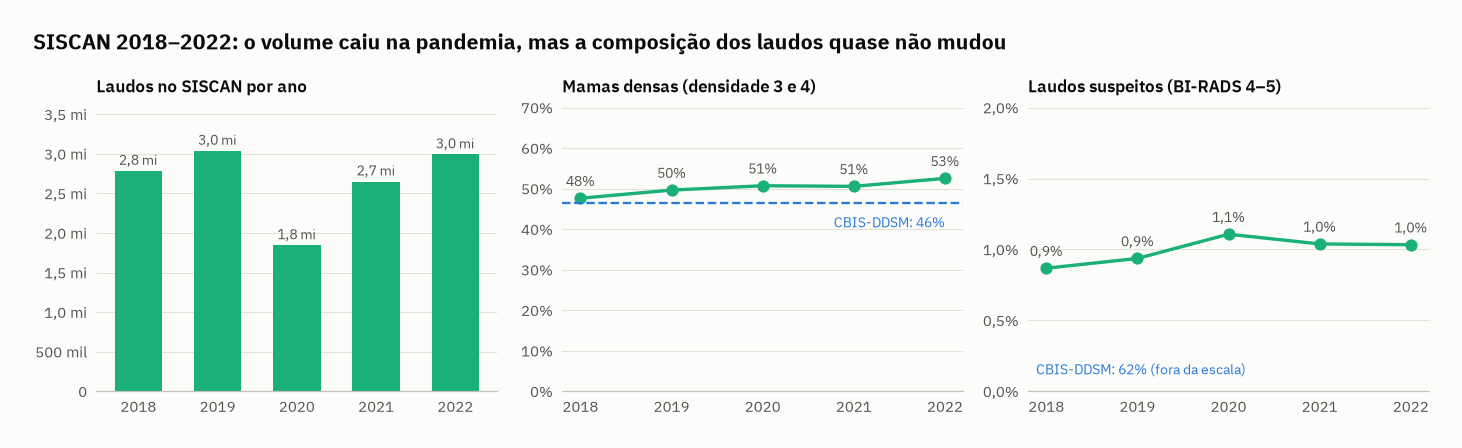

In [9]:
anos = estabilidade.index.astype(str)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))

barras = axes[0].bar(anos, estabilidade["exames (densidade)"], color=VERDE_AGUA, width=0.6)
axes[0].bar_label(barras, labels=[estilo.milhar(v).replace(".", ",") for v in estabilidade["exames (densidade)"]],
                  padding=2, color=estilo.TINTA_SECUNDARIA, fontsize=9)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(estilo.milhar))
axes[0].set_ylim(0, estabilidade["exames (densidade)"].max() * 1.18)
axes[0].set_title("Laudos no SISCAN por ano", fontsize=11)

axes[1].plot(anos, estabilidade["% mamas densas (3+4)"], marker="o", markersize=7, color=VERDE_AGUA)
for xi, yi in zip(anos, estabilidade["% mamas densas (3+4)"]):
    axes[1].annotate(f"{yi:.0f}%", (xi, yi), xytext=(0, 8), textcoords="offset points", ha="center",
                     color=estilo.TINTA_SECUNDARIA, fontsize=9)
axes[1].axhline(cbis_densas, color=AZUL, ls="--", lw=1.5)
axes[1].text(len(anos) - 1, cbis_densas - 6, f"CBIS-DDSM: {cbis_densas:.0f}%", color=AZUL, ha="right", fontsize=9)
axes[1].set_ylim(0, 70)
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
axes[1].set_title("Mamas densas (densidade 3 e 4)", fontsize=11)

axes[2].plot(anos, estabilidade["% BI-RADS 4–5"], marker="o", markersize=7, color=VERDE_AGUA)
for xi, yi in zip(anos, estabilidade["% BI-RADS 4–5"]):
    axes[2].annotate(f"{yi:.1f}%".replace(".", ","), (xi, yi), xytext=(0, 8), textcoords="offset points",
                     ha="center", color=estilo.TINTA_SECUNDARIA, fontsize=9)
axes[2].set_ylim(0, 2)
axes[2].yaxis.set_major_locator(mticker.MultipleLocator(0.5))
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.1f}%".replace(".", ",")))
susp_cbis = birads.loc["suspeitos (4 + 5)", "CBIS-DDSM"]
axes[2].text(0.02, 0.06, f"CBIS-DDSM: {susp_cbis:.0f}% (fora da escala)", transform=axes[2].transAxes,
             color=AZUL, fontsize=9)
axes[2].set_title("Laudos suspeitos (BI-RADS 4–5)", fontsize=11)

fig.suptitle("SISCAN 2018–2022: o volume caiu na pandemia, mas a composição dos laudos quase não mudou",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "26_siscan_estabilidade")

**Leitura:** a composição dos laudos é estável. Em todos os anos, a diferença para o período inteiro é muito
pequena (w ≤ 0,07, tanto na densidade quanto no BI-RADS), inclusive em 2020, quando o número de exames caiu cerca
de 40%: a pandemia mudou a **quantidade** de exames, não o **perfil** das mulheres examinadas. Juntar os cinco
anos, portanto, não distorce a comparação.

Há uma tendência pequena: a proporção de mamas densas sobe de 48% (2018) para 53% (2022). Isso afasta o Brasil um
pouco do CBIS-DDSM (46%) nos anos mais recentes, mas a diferença continua pequena em todos os anos. Os laudos
suspeitos ficam em torno de 1% em todos os anos, muito longe dos 62% do CBIS-DDSM.

## 3. Densidade × dificuldade: o que o Brasil e o modelo mostram

Duas evidências independentes de que **mamas densas são mais difíceis**:

- **Brasil (SISCAN):** proporção de laudos **BI-RADS 0** (inconclusivo, precisa de exames complementares) por densidade;
- **CBIS-DDSM:** AUC do modelo de imagens por densidade (notebook 02).

In [10]:
bd = sis["birads_densidade"].dropna(subset=["densidade_birads_coluna"])
bd = bd[bd["linha"].str.match(r"Categoria [0-5]$")]
tab_bd = bd.pivot_table(index="densidade_birads_coluna", columns="linha", values="exames", aggfunc="sum")
inconclusivo = 100 * tab_bd["Categoria 0"] / tab_bd.sum(axis=1)
suspeito = 100 * (tab_bd["Categoria 4"] + tab_bd["Categoria 5"]) / tab_bd.sum(axis=1)

auc_dens = {int(d): roc_auc_score(g["maligno"], g["prob"]) for d, g in pred.dropna(subset=["breast_density"]).groupby("breast_density")}
dificuldade = pd.DataFrame({"Brasil: % BI-RADS 0": inconclusivo, "Brasil: % BI-RADS 4–5": suspeito,
                            "CBIS: AUC do modelo": pd.Series(auc_dens),
                            "CBIS: n no teste": pred["breast_density"].value_counts()}).rename(index=NOMES_DENS)
dificuldade

,Brasil: % BI-RADS 0,Brasil: % BI-RADS 4–5,CBIS: AUC do modelo,CBIS: n no teste
1 adiposa,7.74,0.71,1.00,24
2 pred. adiposa,10.84,0.90,0.85,115
3 pred. densa,14.15,1.14,0.71,115
4 densa,12.27,1.03,0.52,70


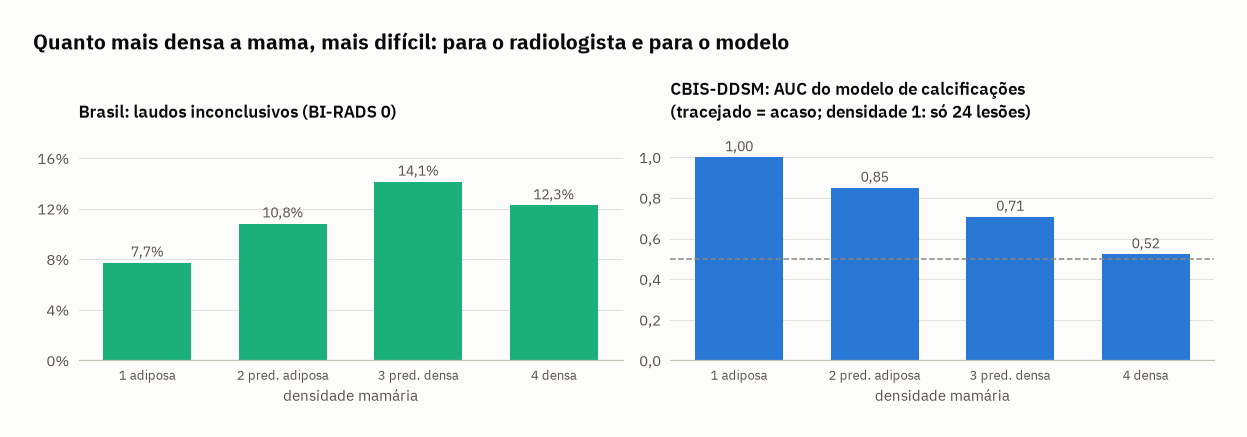

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
cores_dens = estilo.SEQUENCIAL_AZUL[1:5]
barras = axes[0].bar(dificuldade.index, dificuldade["Brasil: % BI-RADS 0"], color=VERDE_AGUA, width=0.65)
axes[0].bar_label(barras, labels=[f"{v:.1f}%".replace(".", ",") for v in dificuldade["Brasil: % BI-RADS 0"]],
                  padding=2, color=estilo.TINTA_SECUNDARIA, fontsize=9)
axes[0].set_ylim(0, 18)
axes[0].yaxis.set_major_locator(mticker.MultipleLocator(4))
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
axes[0].set_title("Brasil: laudos inconclusivos (BI-RADS 0)", fontsize=11)

barras = axes[1].bar(dificuldade.index, dificuldade["CBIS: AUC do modelo"], color=AZUL, width=0.65)
axes[1].bar_label(barras, labels=[f"{v:.2f}".replace(".", ",") for v in dificuldade["CBIS: AUC do modelo"]],
                  padding=2, color=estilo.TINTA_SECUNDARIA, fontsize=9)
axes[1].axhline(0.5, color=estilo.TINTA_SUAVE, ls="--", lw=1)
axes[1].set_ylim(0, 1.12)
axes[1].yaxis.set_major_locator(mticker.MultipleLocator(0.2))
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
axes[1].set_title("CBIS-DDSM: AUC do modelo de calcificações\n(tracejado = acaso; densidade 1: só 24 lesões)", fontsize=11)
for ax in axes:
    ax.tick_params(axis="x", labelsize=8.5)
    ax.set_xlabel("densidade mamária")
fig.suptitle("Quanto mais densa a mama, mais difícil: para o radiologista e para o modelo",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "18_densidade_dificuldade")

## 4. O desempenho do modelo na composição brasileira

O conjunto de teste do CBIS-DDSM tem uma mistura própria de densidades. Para estimar o desempenho com a mistura de
outra população, cada lesão recebe um **peso** igual a (proporção da sua densidade na população-alvo) ÷
(proporção no teste). Depois calculamos a **AUC ponderada**. Populações-alvo:

- Brasil, todas as idades;
- Brasil, por faixa etária: 40–49, 50–69 (faixa-alvo do rastreamento) e 70 ou mais.

**Suposição:** dentro de cada categoria de densidade, o modelo erra igual no CBIS-DDSM e no Brasil. A reponderação
corrige só a **mistura** de densidades, não diferenças de equipamento, população ou prevalência. Os intervalos vêm
de bootstrap (o teste tem 326 lesões).

In [12]:
def dist_faixas(faixas):
    t = tab_fx.loc[[f for f in tab_fx.index if rotulo_faixa(f) in faixas]].sum()
    return t / t.sum()

alvos = {
    "CBIS-DDSM (teste, sem peso)": None,
    "Brasil, todas as idades": br_dens / 100,
    "Brasil, 40–49": dist_faixas(["40–44", "45–49"]),
    "Brasil, 50–69": dist_faixas(["50–54", "55–59", "60–64", "65–69"]),
    "Brasil, 70+": dist_faixas(["70–74", "75–79", "80+"]),
}

base = pred.dropna(subset=["breast_density"]).copy()
p_teste = base["breast_density"].value_counts(normalize=True)

def pesos(alvo, df):
    if alvo is None:
        return np.ones(len(df))
    return df["breast_density"].map(alvo / p_teste).to_numpy()

rng = np.random.default_rng(0)
linhas = []
for nome, alvo in alvos.items():
    auc = roc_auc_score(base["maligno"], base["prob"], sample_weight=pesos(alvo, base))
    boot = []
    for _ in range(1000):
        b = base.iloc[rng.integers(0, len(base), len(base))]
        boot.append(roc_auc_score(b["maligno"], b["prob"], sample_weight=pesos(alvo, b)))
    dens_alvo = (alvo if alvo is not None else p_teste).reindex(DENS)
    linhas.append({"população": nome, "AUC": auc, "IC95% inf": np.percentile(boot, 2.5),
                   "IC95% sup": np.percentile(boot, 97.5), "% densas (3+4)": 100 * dens_alvo[[3, 4]].sum()})
reponderado = pd.DataFrame(linhas).set_index("população")

# sensibilidade: sem a densidade 1 (24 lesões, AUC = 1,00, pesos grandes nas faixas mais velhas)
sem1 = base[base["breast_density"] != 1]
p_teste_sem1 = sem1["breast_density"].value_counts(normalize=True)
def auc_sem1(alvo):
    if alvo is None:
        return roc_auc_score(sem1["maligno"], sem1["prob"])
    a = alvo.reindex([2, 3, 4]) / alvo.reindex([2, 3, 4]).sum()
    return roc_auc_score(sem1["maligno"], sem1["prob"], sample_weight=sem1["breast_density"].map(a / p_teste_sem1))
reponderado["AUC sem densidade 1"] = [auc_sem1(a) for a in alvos.values()]
reponderado.to_csv(config.PROCESSED / "auc_reponderada.csv")  # usado pelo painel
reponderado

,AUC,IC95% inf,IC95% sup,% densas (3+4),AUC sem densidade 1
população,,,,,
"CBIS-DDSM (teste, sem peso)",0.74,0.68,0.79,57.10,0.72
"Brasil, todas as idades",0.76,0.71,0.82,50.21,0.73
"Brasil, 40–49",0.73,0.67,0.78,65.50,0.70
"Brasil, 50–69",0.78,0.72,0.83,44.23,0.74
"Brasil, 70+",0.81,0.75,0.86,33.41,0.76


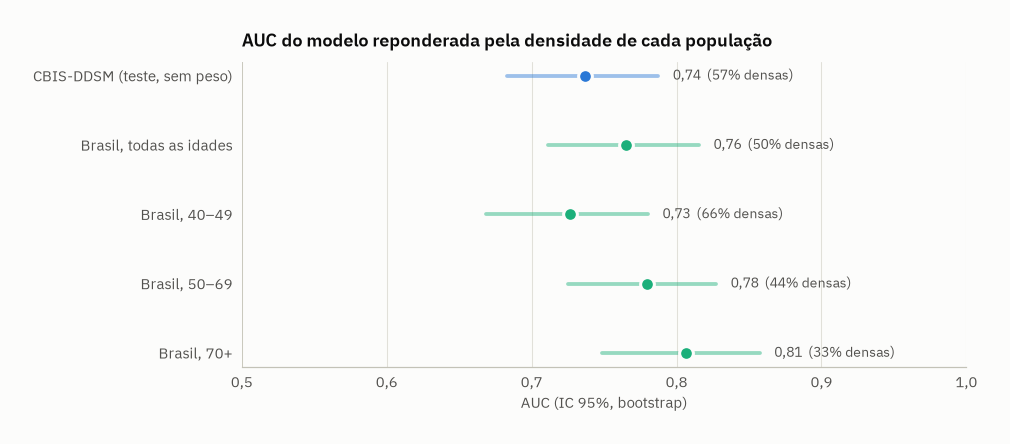

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
y = np.arange(len(reponderado))[::-1]
cores = [AZUL] + [VERDE_AGUA] * (len(reponderado) - 1)
for yi, (nome, r), cor in zip(y, reponderado.iterrows(), cores):
    ax.plot([r["IC95% inf"], r["IC95% sup"]], [yi, yi], color=cor, lw=2.5, alpha=0.45, solid_capstyle="round")
    ax.plot(r["AUC"], yi, "o", color=cor, markersize=9, markeredgecolor=estilo.FUNDO, markeredgewidth=2)
    ax.text(r["IC95% sup"] + 0.01, yi, f"{r['AUC']:.2f}  ({r['% densas (3+4)']:.0f}% densas)".replace(".", ","),
            va="center", color=estilo.TINTA_SECUNDARIA, fontsize=9)
ax.set_yticks(y, reponderado.index)
ax.axvline(0.5, color=estilo.EIXO, lw=1)
ax.set_xlim(0.5, 1.0)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax.set_xlabel("AUC (IC 95%, bootstrap)")
ax.set_title("AUC do modelo reponderada pela densidade de cada população")
salvar(fig, "19_auc_reponderada")

## 5. Qual Brasil? Densidade e BI-RADS por região

Até aqui o Brasil foi tratado como um todo. Com o SISCAN por **UF de residência** (somado por região), comparamos o
CBIS-DDSM com cada região:

- distribuição de densidade e w de Cohen do CBIS-DDSM contra cada região;
- **% de mamas densas padronizada por idade**: as regiões examinam mulheres de idades diferentes, e a densidade
  depende da idade. A padronização aplica a cada região a mesma distribuição etária (a do Brasil), para separar o
  efeito da região do efeito da idade;
- BI-RADS no rastreamento;
- AUC do modelo reponderada pela densidade de cada região (mesmo método da seção 4).

**Cuidado com a cobertura:** a adesão ao SISCAN varia muito. A última coluna da tabela compara os laudos do SISCAN
com as mamografias faturadas no SIA no mesmo período: no Sudeste, o SISCAN tem só cerca de metade dos exames.

In [14]:
ORDEM_REG = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]

def le_uf(nome):
    df = pd.read_csv(I / f"{nome}.csv")
    df = df[df["linha"] != "Ignorado"].copy()
    df["uf"] = df["linha"].str.replace(r"^\d+\s+", "", regex=True)
    df["regiao"] = df["uf"].map(config.UF_PARA_REGIAO)
    return df

dens_uf = le_uf("siscan_densidade_uf").dropna(subset=["densidade_birads_coluna"])
dens_uf["densidade"] = dens_uf["densidade_birads_coluna"].astype(int)
tab_uf = dens_uf.pivot_table(index="uf", columns="densidade", values="exames", aggfunc="sum")[DENS]
tab_reg = tab_uf.groupby(config.UF_PARA_REGIAO).sum().reindex(ORDEM_REG)
dist_reg = tab_reg.div(tab_reg.sum(axis=1), axis=0)
cbis_p = densidades["CBIS: todas as lesões"].to_numpy() / 100

fx_uf = pd.concat([le_uf(f"siscan_uf_faixa_densidade_{d}") for d in DENS])
fx_uf = fx_uf[fx_uf["coluna"] != "Ignorado"].astype({"densidade_birads_filtro": int})
t = fx_uf.pivot_table(index=["regiao", "coluna"], columns="densidade_birads_filtro", values="exames", aggfunc="sum").fillna(0)
p_densa = ((t[3] + t[4]) / t.sum(axis=1)).unstack("coluna")
n_idade = t.sum(axis=1).unstack("coluna")
peso_idade = n_idade.sum() / n_idade.sum().sum()

bi_uf = le_uf("siscan_birads_uf")
bi_uf = bi_uf[bi_uf["coluna"].str.match(r"Categoria [0-5]$")]
tb = bi_uf.pivot_table(index="regiao", columns="coluna", values="exames", aggfunc="sum").reindex(ORDEM_REG)
tb = 100 * tb.div(tb.sum(axis=1), axis=0)

sia_uf = pd.concat([pd.read_csv(I / f"datasus_sia_mamografia_{f}_uf_ano.csv").query("nivel == 'uf'")
                    for f in ["rastreamento", "diagnostica"]])
sia_reg = sia_uf.groupby(sia_uf["localidade"].map(config.UF_PARA_REGIAO))["valor"].sum()

regioes_siscan = pd.DataFrame({
    "laudos SISCAN": tab_reg.sum(axis=1),
    "% mamas densas": 100 * (dist_reg[3] + dist_reg[4]),
    "% densas padronizada por idade": 100 * p_densa.mul(peso_idade, axis=1).sum(axis=1),
    "% exames entre 40 e 49 anos": 100 * n_idade[["Entre 40 a 44 anos", "Entre 45 a 49 anos"]].sum(axis=1) / n_idade.sum(axis=1),
    "w CBIS-DDSM × região": pd.Series({r: w_cohen(cbis_p, dist_reg.loc[r].to_numpy()) for r in ORDEM_REG}),
    "% BI-RADS 0 (rastreamento)": tb["Categoria 0"],
    "% BI-RADS 4–5 (rastreamento)": tb["Categoria 4"] + tb["Categoria 5"],
    "SISCAN ÷ SIA (%)": 100 * tab_reg.sum(axis=1) / sia_reg,
}).reindex(ORDEM_REG)
display((100 * dist_reg).round(1).rename(columns=NOMES_DENS))
regioes_siscan.round(2)

densidade,1 adiposa,2 pred. adiposa,3 pred. densa,4 densa
uf,,,,
Norte,12.60,22.10,39.70,25.60
Nordeste,15.10,34.30,33.30,17.30
Centro-Oeste,16.30,29.80,38.10,15.80
Sudeste,16.10,36.60,32.90,14.50
Sul,16.40,33.10,35.50,15.00


,laudos SISCAN,% mamas densas,% densas padronizada por idade,% exames entre 40 e 49 anos,w CBIS-DDSM × região,% BI-RADS 0 (rastreamento),% BI-RADS 4–5 (rastreamento),SISCAN ÷ SIA (%)
Norte,"543,063.00",65.26,62.90,35.37,0.43,11.44,1.23,93.03
Nordeste,"3,933,875.00",50.59,50.17,28.65,0.09,12.79,0.84,93.61
Centro-Oeste,"858,662.00",53.90,52.46,32.75,0.20,11.55,1.09,108.13
Sudeste,"4,915,610.00",47.40,48.04,25.11,0.06,11.50,0.84,51.21
Sul,"3,063,849.00",50.52,50.77,25.97,0.13,10.21,0.92,82.24


In [15]:
rng = np.random.default_rng(0)
auc_reg = []
for r in ORDEM_REG:
    alvo = dist_reg.loc[r]
    boot = []
    for _ in range(1000):
        b = base.iloc[rng.integers(0, len(base), len(base))]
        boot.append(roc_auc_score(b["maligno"], b["prob"], sample_weight=pesos(alvo, b)))
    auc_reg.append({"regiao": r, "AUC": roc_auc_score(base["maligno"], base["prob"], sample_weight=pesos(alvo, base)),
                    "IC95% inf": np.percentile(boot, 2.5), "IC95% sup": np.percentile(boot, 97.5)})
auc_reg = pd.DataFrame(auc_reg).set_index("regiao")
regioes_siscan = regioes_siscan.join(auc_reg)

densas_uf = (100 * (tab_uf[3] + tab_uf[4]) / tab_uf.sum(axis=1)).rename("% mamas densas").to_frame()
densas_uf["regiao"] = densas_uf.index.map(config.UF_PARA_REGIAO)
densas_uf["laudos SISCAN"] = tab_uf.sum(axis=1)
regioes_siscan.to_csv(config.PROCESSED / "siscan_regiao.csv", index_label="regiao")  # usado pelo painel
densas_uf.to_csv(config.PROCESSED / "siscan_densidade_uf.csv", index_label="uf")    # usado pelo painel
regioes_siscan[["% mamas densas", "w CBIS-DDSM × região", "AUC", "IC95% inf", "IC95% sup"]].round(2)

,% mamas densas,w CBIS-DDSM × região,AUC,IC95% inf,IC95% sup
Norte,65.26,0.43,0.73,0.67,0.78
Nordeste,50.59,0.09,0.76,0.71,0.81
Centro-Oeste,53.90,0.20,0.76,0.70,0.81
Sudeste,47.40,0.06,0.77,0.72,0.82
Sul,50.52,0.13,0.77,0.71,0.82


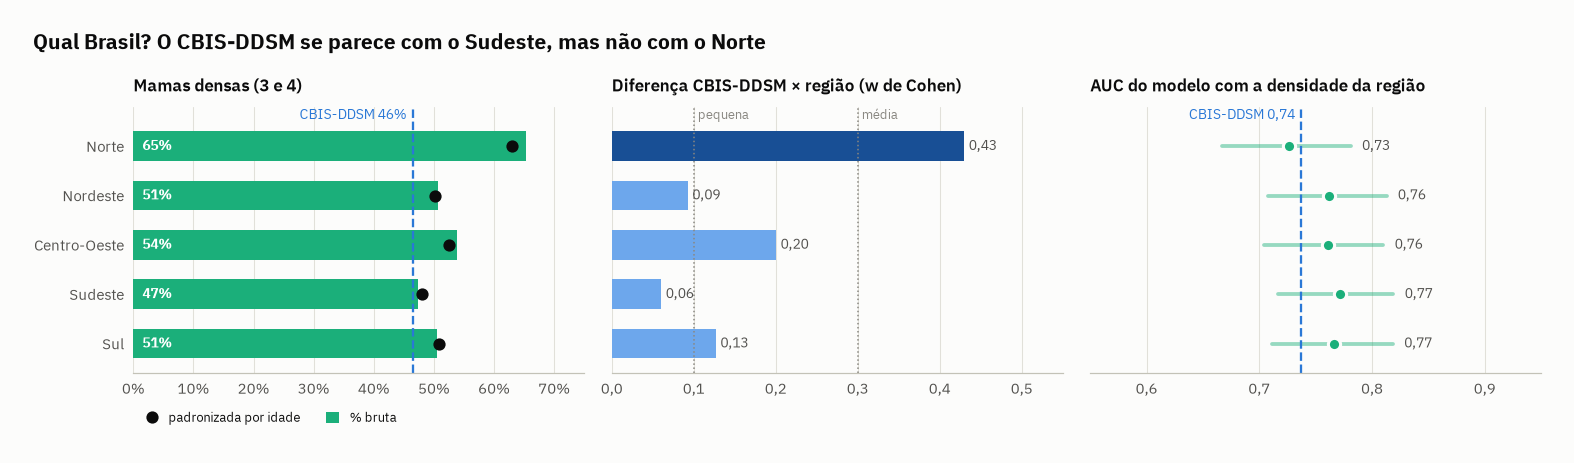

In [16]:
r = regioes_siscan.iloc[::-1]
y = np.arange(len(r))
auc_cbis = reponderado.loc["CBIS-DDSM (teste, sem peso)", "AUC"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)

ax = axes[0]
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.barh(y, r["% mamas densas"], color=VERDE_AGUA, height=0.6, label="% bruta")
ax.plot(r["% densas padronizada por idade"], y, "o", color=estilo.TINTA, markersize=7, label="padronizada por idade")
for yi, v in zip(y, r["% mamas densas"]):
    ax.text(1.5, yi, f"{v:.0f}%", va="center", fontsize=9, color="white", fontweight="bold")
ax.axvline(cbis_densas, color=AZUL, ls="--", lw=1.5)
ax.text(cbis_densas - 1, len(r) - 0.45, f"CBIS-DDSM {cbis_densas:.0f}%", color=AZUL, fontsize=9, ha="right")
ax.set_xlim(0, 75)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=2, fontsize=8.5)
ax.set_title("Mamas densas (3 e 4)", fontsize=11)

ax = axes[1]
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
cores_w = [estilo.SEQUENCIAL_AZUL[5] if w >= 0.3 else estilo.SEQUENCIAL_AZUL[2] for w in r["w CBIS-DDSM × região"]]
barras = ax.barh(y, r["w CBIS-DDSM × região"], color=cores_w, height=0.6)
ax.bar_label(barras, labels=[f"{w:.2f}".replace(".", ",") for w in r["w CBIS-DDSM × região"]], padding=3,
             fontsize=9, color=estilo.TINTA_SECUNDARIA)
for limite, rotulo in [(0.1, "pequena"), (0.3, "média")]:
    ax.axvline(limite, color=estilo.TINTA_SUAVE, lw=1, ls=":")
    ax.text(limite + 0.005, len(r) - 0.45, rotulo, fontsize=8.5, color=estilo.TINTA_SUAVE)
ax.set_xlim(0, 0.55)
ax.set_title("Diferença CBIS-DDSM × região (w de Cohen)", fontsize=11)

ax = axes[2]
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
for yi, (_, l) in zip(y, r.iterrows()):
    ax.plot([l["IC95% inf"], l["IC95% sup"]], [yi, yi], color=VERDE_AGUA, lw=2.5, alpha=0.45, solid_capstyle="round")
    ax.plot(l["AUC"], yi, "o", color=VERDE_AGUA, markersize=8, markeredgecolor=estilo.FUNDO, markeredgewidth=2)
    ax.text(l["IC95% sup"] + 0.01, yi, f"{l['AUC']:.2f}".replace(".", ","), va="center", fontsize=9,
            color=estilo.TINTA_SECUNDARIA)
ax.axvline(auc_cbis, color=AZUL, ls="--", lw=1.5)
ax.text(auc_cbis - 0.005, len(r) - 0.45, f"CBIS-DDSM {auc_cbis:.2f}".replace(".", ","), color=AZUL, fontsize=9, ha="right")
ax.set_xlim(0.55, 0.95)
ax.xaxis.set_major_locator(mticker.MultipleLocator(0.1))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax.set_title("AUC do modelo com a densidade da região", fontsize=11)

axes[0].set_yticks(y, r.index)
axes[0].set_ylim(-0.6, len(r) - 0.2)
fig.suptitle("Qual Brasil? O CBIS-DDSM se parece com o Sudeste, mas não com o Norte", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
salvar(fig, "28_densidade_por_regiao")

,% mamas densas,regiao,laudos SISCAN
uf,,,
Amapá,78.80,Norte,"11,303.00"
Acre,70.40,Norte,"44,609.00"
Ceará,68.60,Nordeste,"458,590.00"
Rondônia,68.20,Norte,"72,926.00"
Roraima,65.60,Norte,"20,688.00"
Pará,65.30,Norte,"253,354.00"
Amazonas,63.50,Norte,"93,308.00"
Sergipe,62.30,Nordeste,"208,677.00"


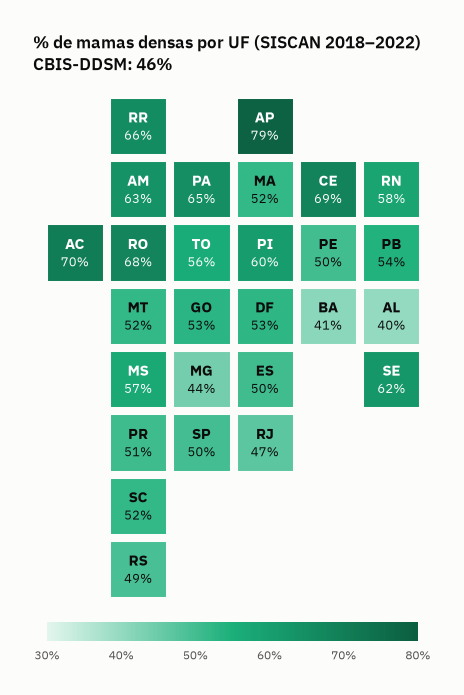

In [17]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle

from src.visualization.painel_dados import SIGLAS

GRADE_UF = {
    "RR": (0, 1), "AP": (0, 3),
    "AM": (1, 1), "PA": (1, 2), "MA": (1, 3), "CE": (1, 4), "RN": (1, 5),
    "AC": (2, 0), "RO": (2, 1), "TO": (2, 2), "PI": (2, 3), "PE": (2, 4), "PB": (2, 5),
    "MT": (3, 1), "GO": (3, 2), "DF": (3, 3), "BA": (3, 4), "AL": (3, 5),
    "MS": (4, 1), "MG": (4, 2), "ES": (4, 3), "SE": (4, 5),
    "PR": (5, 1), "SP": (5, 2), "RJ": (5, 3),
    "SC": (6, 1),
    "RS": (7, 1),
}
por_sigla = densas_uf.rename(index=SIGLAS)["% mamas densas"]
cmap = LinearSegmentedColormap.from_list("seq_verde", ["#e3f6ee", VERDE_AGUA, "#0b5e40"])
norm = Normalize(vmin=30, vmax=80)

fig, ax = plt.subplots(figsize=(5.8, 6.6))
for sigla, (lin, col) in GRADE_UF.items():
    v = por_sigla[sigla]
    ax.add_patch(Rectangle((col, -lin), 0.92, 0.92, facecolor=cmap(norm(v)), edgecolor=estilo.FUNDO, lw=2))
    tinta = "white" if norm(v) > 0.5 else estilo.TINTA
    ax.text(col + 0.46, -lin + 0.58, sigla, ha="center", va="center", fontsize=9.5, fontweight="bold", color=tinta)
    ax.text(col + 0.46, -lin + 0.30, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color=tinta)
ax.set_xlim(-0.2, 6.1)
ax.set_ylim(-7.2, 1.1)
ax.set_aspect("equal")
ax.axis("off")
barra = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, orientation="horizontal",
                     fraction=0.04, pad=0.02, shrink=0.75, format=mticker.PercentFormatter(decimals=0))
barra.outline.set_visible(False)
barra.ax.tick_params(labelsize=8, colors=estilo.TINTA_SUAVE, labelcolor=estilo.TINTA_SECUNDARIA)
ax.set_title(f"% de mamas densas por UF (SISCAN 2018–2022)\nCBIS-DDSM: {cbis_densas:.0f}%", fontsize=11)
salvar(fig, "29_mapa_densidade_uf")
densas_uf.sort_values("% mamas densas", ascending=False).round(1).head(8)

### 5.1 Seis indicadores no mapa do Brasil

Os mesmos dados por UF, agora no mapa geográfico (malha oficial do IBGE), lado a lado. As cores vão do valor mais
baixo ao mais alto de cada indicador; o contorno escuro separa as regiões. No mapa geográfico, estados grandes como
Amazonas e Pará chamam mais atenção do que o seu peso na população; o mapa em grade acima evita esse efeito.

,Incidência ajustada,Óbitos por 100 mil mulheres,Rastreamentos no SUS,Óbitos (2022) por caso,Mamas densas,Diferença para o CBIS-DDSM
AC,26.20,7.55,22.92,0.34,70.41,0.57
AL,34.89,12.56,42.45,0.32,40.10,0.18
AP,20.04,6.01,22.17,0.36,78.81,0.80
AM,28.34,10.38,9.59,0.46,63.48,0.48
BA,43.28,13.92,38.29,0.26,41.00,0.15
CE,54.13,15.73,21.31,0.25,68.56,0.50
DF,49.76,15.77,6.28,0.25,52.52,0.39
ES,32.94,16.83,34.89,0.40,50.43,0.20
GO,45.63,15.21,23.84,0.29,52.91,0.29
MA,28.29,7.92,16.38,0.28,51.93,0.16


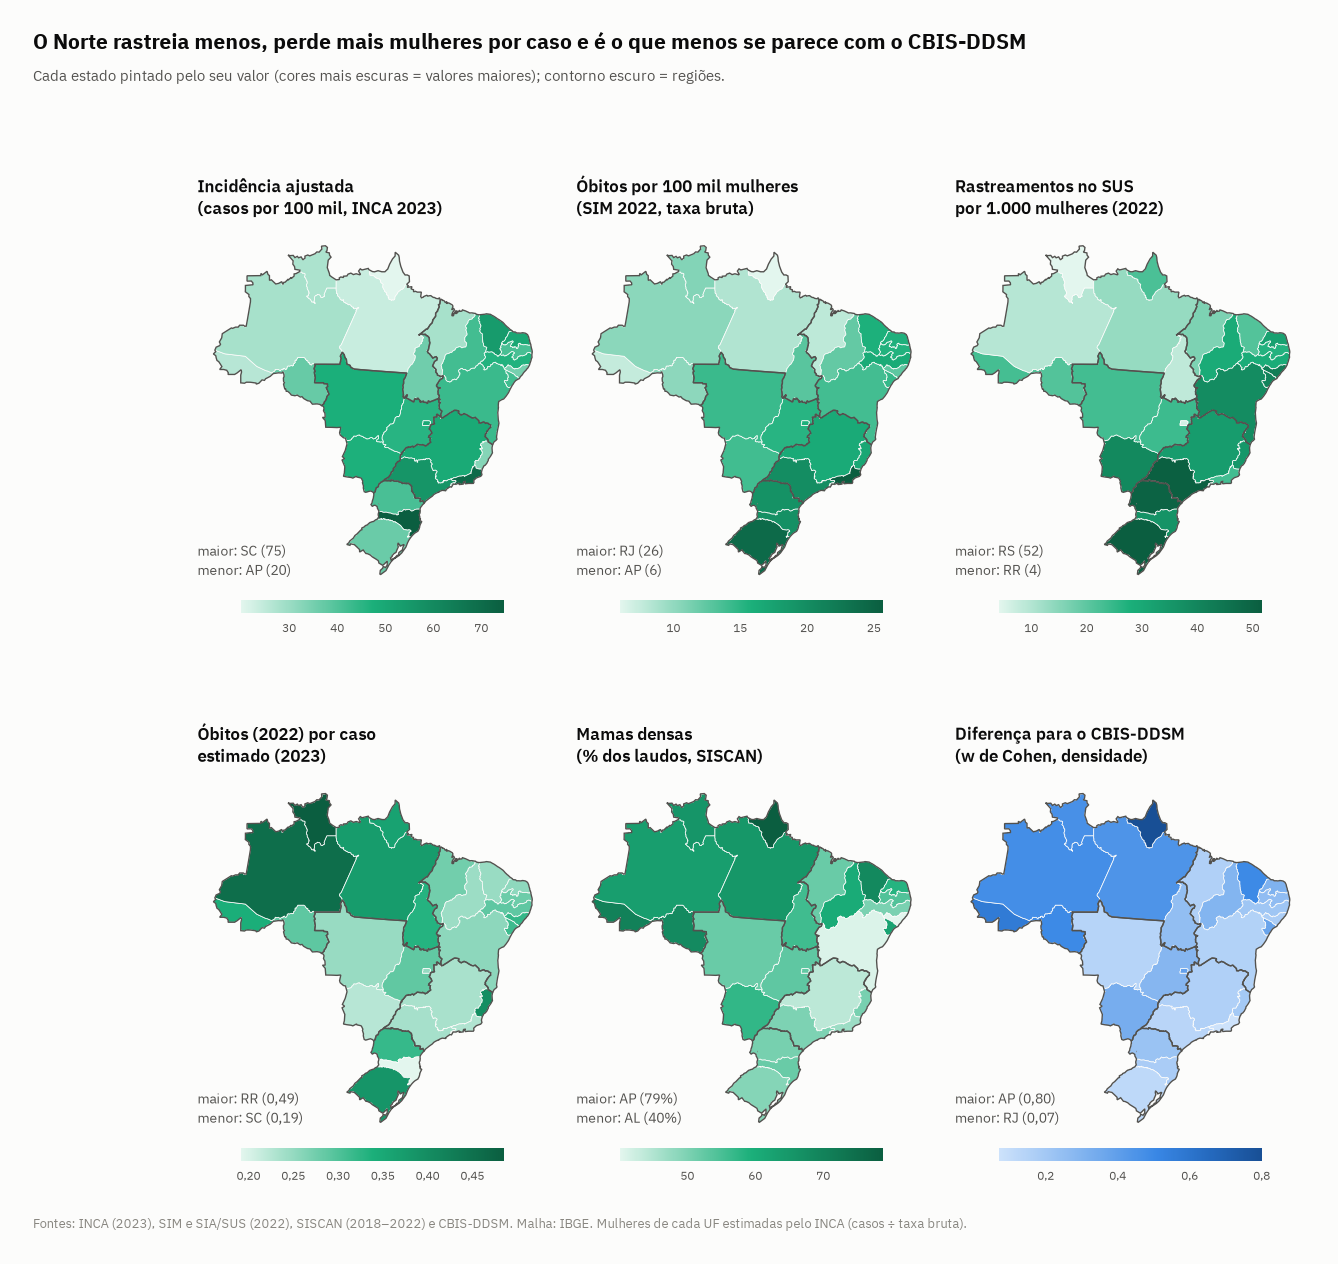

In [18]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from src.visualization import mapa

uf_inc = (pd.read_csv(I / "inca_incidencia.csv").query("nivel == 'uf'")
          .pivot_table(index="localidade", columns="indicador", values="valor"))
mulheres = uf_inc["casos_estimados"] / uf_inc["taxa_bruta_100mil"] * 1e5

def uf_2022(arquivo):
    return pd.read_csv(I / f"{arquivo}.csv").query("nivel == 'uf' and ano == 2022").set_index("localidade")["valor"]

rast_uf = uf_2022("datasus_sia_mamografia_rastreamento_uf_ano")
obitos_uf = uf_2022("datasus_sim_obitos_mama_uf_ano")
dist_uf = tab_uf.div(tab_uf.sum(axis=1), axis=0)
indicadores_uf = pd.DataFrame({
    "Incidência ajustada\n(casos por 100 mil, INCA 2023)": uf_inc["taxa_ajustada_100mil"],
    "Óbitos por 100 mil mulheres\n(SIM 2022, taxa bruta)": 1e5 * obitos_uf / mulheres,
    "Rastreamentos no SUS\npor 1.000 mulheres (2022)": 1000 * rast_uf / mulheres,
    "Óbitos (2022) por caso\nestimado (2023)": obitos_uf / uf_inc["casos_estimados"],
    "Mamas densas\n(% dos laudos, SISCAN)": densas_uf["% mamas densas"],
    "Diferença para o CBIS-DDSM\n(w de Cohen, densidade)": pd.Series(
        {u: w_cohen(cbis_p, dist_uf.loc[u].to_numpy()) for u in dist_uf.index}),
}).rename(index=SIGLAS)
formatos = ["{:.0f}", "{:.0f}", "{:.0f}", "{:.2f}", "{:.0f}%", "{:.2f}"]
verde = LinearSegmentedColormap.from_list("verde", ["#e3f6ee", VERDE_AGUA, "#0b5e40"])
azul = LinearSegmentedColormap.from_list("azul", estilo.SEQUENCIAL_AZUL[:6])

fig, axes = plt.subplots(2, 3, figsize=(13, 10))
for ax, coluna, fmt in zip(axes.flat, indicadores_uf.columns, formatos):
    s = indicadores_uf[coluna]
    cmap = azul if "CBIS" in coluna else verde
    norm = Normalize(s.min(), s.max())
    mapa.desenha(ax, s.to_dict(), cmap, norm)
    ax.set_title(coluna, fontsize=11)
    ax.text(0.0, 0.03, f"maior: {s.idxmax()} ({fmt.format(s.max())})\nmenor: {s.idxmin()} ({fmt.format(s.min())})",
            transform=ax.transAxes, fontsize=9, color=estilo.TINTA_SECUNDARIA, va="bottom", linespacing=1.4)
    barra = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, orientation="horizontal",
                         fraction=0.04, pad=0.02, shrink=0.75)
    barra.outline.set_visible(False)
    barra.ax.tick_params(labelsize=8, colors=estilo.TINTA_SUAVE, labelcolor=estilo.TINTA_SECUNDARIA)
fig.subplots_adjust(wspace=0.08, hspace=0.18, bottom=0.03)
estilo.cabecalho(fig, "O Norte rastreia menos, perde mais mulheres por caso e é o que menos se parece com o CBIS-DDSM",
                 "Cada estado pintado pelo seu valor (cores mais escuras = valores maiores); contorno escuro = regiões.")
estilo.rodape(fig, "Fontes: INCA (2023), SIM e SIA/SUS (2022), SISCAN (2018–2022) e CBIS-DDSM. Malha: IBGE. "
                   "Mulheres de cada UF estimadas pelo INCA (casos ÷ taxa bruta).")
salvar(fig, "30_mapas_uf")
indicadores_uf.set_axis([c.split("\n")[0] for c in indicadores_uf.columns], axis=1).round(2)

**Leitura:**

- **Norte:** a menor incidência registrada e a menor cobertura de rastreamento (Roraima, Amazonas, Pará e Tocantins
  têm os valores mais baixos), mas a maior razão entre óbitos e casos (Roraima e Amazonas). É também onde as mamas
  são mais densas (Amapá, 79%) e, por isso, onde a distribuição de densidade mais se afasta do CBIS-DDSM (Amapá,
  w = 0,80).
- **Sul e Sudeste:** incidência, mortalidade e rastreamento mais altos, e densidade parecida com a do CBIS-DDSM
  (Rio de Janeiro, w = 0,07).
- Os mapas repetem, por estado, o que as regiões já mostravam: a base se parece com o Brasil mais rastreado e
  menos com o Brasil em que o diagnóstico parece chegar mais tarde.
- Os indicadores de óbitos por caso e por mulheres usam estimativas do INCA e oscilam mais nas UFs pequenas
  (Roraima, Amapá, Acre); a direção do padrão importa mais do que o valor de cada estado.

**Leitura:**

- **O CBIS-DDSM se parece com o Sudeste, e não com o Norte.** No Sudeste, 47% das mamas são densas, praticamente o
  mesmo que no CBIS-DDSM (46%; w = 0,06). No Norte são 65% (w = 0,43, entre "média" e "grande"). As UFs com mais
  mamas densas são quase todas do Norte: Amapá (79%), Acre (70%), Rondônia (68%), Roraima (66%) e Pará (65%); fora
  dele, Ceará (69%) e Sergipe (62%).
- **A diferença não vem só da idade.** O Norte examina mulheres mais jovens (35% dos exames entre 40 e 49 anos, contra
  25% no Sudeste), mas, padronizando pela mesma distribuição etária, continua com 63% de mamas densas. Nas demais
  regiões a padronização muda menos de 2 pontos percentuais.
- **O modelo iria pior justamente no Norte:** AUC estimada de 0,73, contra 0,76–0,77 nas outras regiões. Os
  intervalos se sobrepõem, então vale a direção, não o tamanho exato.
- **BI-RADS:** em todas as regiões, os laudos suspeitos (4–5) no rastreamento ficam entre 0,8% e 1,2%. A
  incompatibilidade com o CBIS-DDSM (62%) é a mesma em todo o país.
- **Juntando com o notebook 01:** o Norte já é a região com menor cobertura de rastreamento e maior razão entre
  óbitos e casos. É também onde as mamas são mais densas e onde um modelo treinado no CBIS-DDSM teria o pior
  desempenho. A população mais vulnerável é a menos representada pela base.

**Cuidados:** a classificação do tipo de mama no laudo é subjetiva, e parte da diferença regional pode vir de
práticas diferentes de laudo, não só das mulheres. A cobertura do SISCAN também varia (no Sudeste, o SISCAN tem cerca
de metade dos exames faturados no SIA).

## 6. Conclusões

**1. Densidade, no total: o CBIS-DDSM é compatível com o Brasil.** Brasil 16/34/34/16% contra CBIS-DDSM
15/39/31/16% (w de Cohen = 0,10, diferença pequena). A hipótese do notebook 02, de que as brasileiras teriam mamas
mais densas, **não se confirma no agregado**. Nos subconjuntos o quadro muda: as massas do CBIS-DDSM estão em mamas
menos densas (w = 0,30) e as calcificações, em mamas mais densas (w = 0,19).

**2. A densidade é dominada pela idade, e a idade é justamente o que o CBIS-DDSM não tem.** No Brasil, 68% das
mamas são densas entre 40 e 44 anos, contra 35% entre 65 e 69. Os 46% de mamas densas do CBIS-DDSM equivalem ao
perfil de uma brasileira de **cerca de 55 anos**. Coincidir no total não garante que a base cubra bem as mulheres
jovens, que são **27% do rastreamento do SUS** (notebook 01).

**3. BI-RADS: o tipo de caso é completamente diferente.** No rastreamento do SUS, 0,9% dos laudos são suspeitos
(BI-RADS 4 ou 5) e 86% são normais ou benignos (1 ou 2). No CBIS-DDSM, **62% são suspeitos** e quase não há
BI-RADS 1. Mesmo as mamografias diagnósticas do SUS têm só 5% de suspeitos. Isso confirma, com outra fonte, a
diferença de prevalência já vista no notebook 01.

**4. Mamas densas são mais difíceis para o radiologista e para o modelo.** No Brasil, o laudo inconclusivo
(BI-RADS 0) sobe de 7,7% em mamas adiposas para 14,1% em mamas predominantemente densas. No CBIS-DDSM, a AUC do
modelo cai de 0,85 (densidade 2) para 0,52 (densidade 4).

**5. Desempenho estimado na composição brasileira.** Reponderando pela densidade:

| População | AUC | AUC sem densidade 1 |
|---|---|---|
| CBIS-DDSM (teste) | 0,74 | 0,72 |
| Brasil, todas as idades | 0,76 | 0,73 |
| Brasil, 40–49 | **0,73** | **0,70** |
| Brasil, 70+ | **0,81** | **0,76** |

No agregado, o desempenho "no Brasil" seria parecido com o medido na base. Mas ele é pior nas mulheres de 40 a
49 anos e melhor nas mais velhas. A diferença se mantém sem a densidade 1, embora menor. Os intervalos de
confiança se sobrepõem, então a direção do efeito é mais robusta do que o tamanho.

**6. Os dados brasileiros são estáveis no período.** De 2018 a 2022, a distribuição de densidade e de BI-RADS no SISCAN
muda muito pouco de um ano para outro (w ≤ 0,07), inclusive em 2020, com a pandemia. Juntar os cinco anos não
distorce a comparação. A proporção de mamas densas sobe um pouco (48% → 53%), sem mudar as conclusões.

**7. Qual Brasil: o CBIS-DDSM se parece com o Sudeste, não com o Norte.** Por região, as mamas densas vão de 47% (Sudeste,
w = 0,06 contra o CBIS-DDSM) a 65% (Norte, w = 0,43). A diferença do Norte se mantém padronizando pela idade (63%).
O modelo teria o pior desempenho estimado no Norte (AUC 0,73), que já é a região com menor cobertura de rastreamento
e maior razão entre óbitos e casos (notebook 01).

### Resposta à pergunta do trabalho

> *Em que medida as características dos casos do CBIS-DDSM são compatíveis com o perfil epidemiológico do câncer de
> mama no Brasil?*

- **Densidade mamária:** compatível no agregado.
- **Composição dos casos (BI-RADS e prevalência de câncer):** incompatível. O CBIS-DDSM é um conjunto de lesões
  suspeitas, não uma amostra de mulheres rastreadas. Métricas como VPP e taxa de falsos positivos não se
  transferem.
- **Região:** compatível com o Sudeste e o Nordeste; incompatível com o Norte, onde as mamas são bem mais densas,
  mesmo descontando a idade.
- **Idade:** impossível verificar. Como a idade determina a densidade, e a densidade determina o desempenho, essa
  ausência esconde exatamente o subgrupo em que o modelo vai pior: as mulheres mais jovens, com mamas mais densas.

O risco principal não está em "o CBIS-DDSM ser diferente do Brasil na média". Está em a média esconder diferenças
entre subgrupos que a base não permite identificar.

### Limitações

- O SISCAN cobre cerca de 70% das mamografias do SUS (3,0 milhões contra 4,25 milhões no SIA em 2022), e a adesão
  varia entre estados. A unidade é o exame, não a mulher.
- A densidade do Brasil é a da mama direita; a esquerda é praticamente igual.
- A reponderação supõe que, **dentro de cada densidade**, o modelo erra igual no CBIS-DDSM e no Brasil. Ela não
  corrige diferenças de equipamento (o CBIS-DDSM é de filmes digitalizados dos anos 1990; o SUS usa mamógrafos
  analógicos e digitais), de população ou de prevalência.
- O conjunto de teste é pequeno (326 lesões; 24 com densidade 1).
- Por região, a adesão ao SISCAN vai de cerca de 50% (Sudeste) a mais de 90% (Norte, Nordeste e Centro-Oeste) dos
  exames faturados no SIA. A classificação do tipo de mama no laudo é subjetiva e pode variar entre regiões.